<a href="https://colab.research.google.com/github/AbigailSeyoum-Data110-Fall2026-CRN21802/AbigailSeyoum-DATA110/blob/main/Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
education = pd.read_csv("/Choose_Maryland___Compare_Counties_Education.csv")
education = education[["County", "Annual Number of Public High School Graduates", "Public School Student-Teacher Ratio", "Bachelor's Degree Attainment (%)"]]
target_counties = ["Montgomery County", "Baltimore County", "Anne Arundel County", "Howard County", "Prince George's County"]
education = education[education["County"].isin(target_counties)]
education = education.sort_values(["County", "Annual Number of Public High School Graduates"])

print(len(education), "counties")
education.head()


5 counties


,County,Annual Number of Public High School Graduates,Public School Student-Teacher Ratio,Bachelor's Degree Attainment (%)
1,Anne Arundel County,5268,14.7,40.9
3,Baltimore County,7171,15.1,38.6
13,Howard County,4025,13.3,61.4
15,Montgomery County,10970,14.5,59
16,Prince George's County,7898,14,32.7


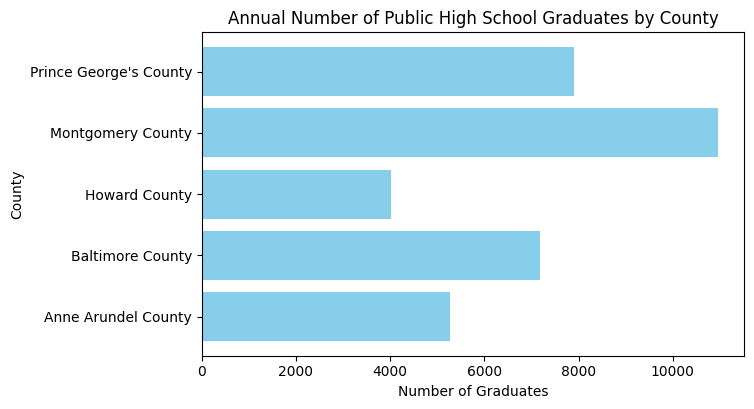

In [ ]:
education["Annual Number of Public High School Graduates"] = pd.to_numeric(education["Annual Number of Public High School Graduates"], errors='coerce')

target_counties = ["Montgomery County", "Baltimore County", "Anne Arundel County", "Howard County", "Prince George's County"]
education = education[education["County"].isin(target_counties)]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(education["County"], education["Annual Number of Public High School Graduates"], color="skyblue")
ax.set_title("Annual Number of Public High School Graduates by County")
ax.set_xlabel("Number of Graduates")
ax.set_ylabel("County")

plt.show()

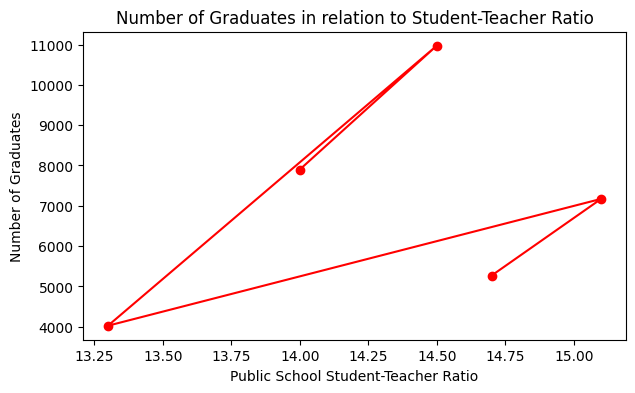

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

education["Annual Number of Public High School Graduates"] = pd.to_numeric(education["Annual Number of Public High School Graduates"], errors='coerce')

target_counties = ["Montgomery County", "Baltimore County", "Anne Arundel County", "Howard County", "Prince George's County"]
education = education[education["County"].isin(target_counties)]

education["Public School Student-Teacher Ratio"] = pd.to_numeric(education["Public School Student-Teacher Ratio"], errors='coerce')
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(education["Public School Student-Teacher Ratio"], education["Annual Number of Public High School Graduates"], marker = 'o', color="red")
ax.set_title("Number of Graduates in relation to Student-Teacher Ratio")
ax.set_xlabel("Public School Student-Teacher Ratio")
ax.set_ylabel("Number of Graduates")
plt.show()

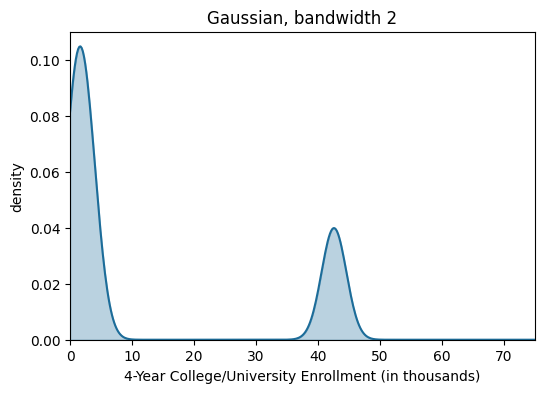

In [ ]:
education["Annual Number of Public High School Graduates"] = pd.to_numeric(education["Annual Number of Public High School Graduates"], errors='coerce')

target_counties = ["Montgomery County", "Baltimore County", "Anne Arundel County", "Howard County", "Prince George's County"]
education = education[education["County"].isin(target_counties)]

def density(data, grid, bw, kernel="gaussian"):
    data_arr = np.asarray(data.dropna(), dtype=float)
    grid_arr = np.asarray(grid, dtype=float)
    distance = grid_arr[:, None] - data_arr[None, :]
    if kernel == "gaussian":
        height = np.exp(-0.5 * (distance / bw) ** 2) / (bw * np.sqrt(2 * np.pi))
    else:
        height = np.zeros_like(distance)
    return height.mean(axis=1)

grid = np.linspace(0, 75, 400)
y = density(enroll_k, grid, bw=2)

fig, ax = plt.subplots(figsize=(6, 4))

ax.fill_between(grid, y, color="#1C6C99", alpha=0.3)
ax.plot(grid, y, color="#1C6C99")
ax.set_xlim(0, 75)
ax.set_ylim(0, None)
ax.set_xlabel("4-Year College/University Enrollment (in thousands)")
ax.set_ylabel("density")
ax.set_title("Gaussian, bandwidth 2")
plt.show()